4) OUTLIER DETECTION


      Gender     Height      Weight
994     Male  78.095867  255.690835
1317    Male  78.462053  227.342565
2014    Male  78.998742  269.989699
3285    Male  78.528210  253.889004
3757    Male  78.621374  245.733783
6624  Female  54.616858   71.393749
7294  Female  54.873728   78.606670
9285  Female  54.263133   64.700127
Outliers found: 8 of 10000


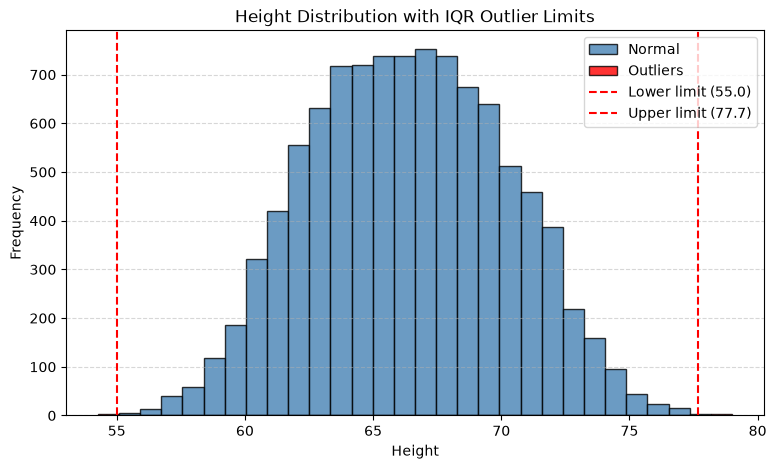

      Gender     Height      Weight
994     Male  78.095867  255.690835
1317    Male  78.462053  227.342565
2014    Male  78.998742  269.989699
3285    Male  78.528210  253.889004
3757    Male  78.621374  245.733783
6624  Female  54.616858   71.393749
9285  Female  54.263133   64.700127


In [ ]:
# Use of IQR method

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("weight-height.csv")

Q1 = df['Height'].quantile(0.25)
Q3 = df['Height'].quantile(0.75)
# print("Q1:", Q1, " Q3:", Q3)

IQR = Q3 - Q1
# print("IQR:", IQR)

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR
# print("Lower limit:", lower_limit, "Upper limit:", upper_limit)

outlier_mask = (df['Height'] < lower_limit) | (df['Height'] > upper_limit)

result = df[outlier_mask]
result_no_outlier = df[~outlier_mask] 

print(result)
print("Outliers found:", len(result), "of", len(df))




# Histogram plot 

# Same bin edges for both histograms so bar widths match
bins = np.histogram_bin_edges(df['Height'], bins=30)

plt.figure(figsize=(9, 5))

# Normal values and outliers in different colors
plt.hist(result_no_outlier['Height'], bins=bins, color="steelblue",
         edgecolor="black", alpha=0.8, label="Normal")
plt.hist(result['Height'], bins=bins, color="red",
         edgecolor="black", alpha=0.8, label="Outliers")

# Vertical lines for the limits
plt.axvline(lower_limit, color="red", linestyle="--", label=f"Lower limit ({lower_limit:.1f})")
plt.axvline(upper_limit, color="red", linestyle="--", label=f"Upper limit ({upper_limit:.1f})")

plt.title("Height Distribution with IQR Outlier Limits")
plt.xlabel("Height")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()



# Uing standard deviation method

mean=df['Height'].mean()
std=df['Height'].std()
mean,std

lower=mean-3*std
upper=mean+3*std

outlier=(df['Height'] < lower) | (df['Height'] > upper)

result=df[outlier]
result_not=df[~outlier]

print(result)


